First 5 rows of the dataset:
   Hours Studied  Previous Scores Extracurricular Activities  Sleep Hours  \
0              7               99                        Yes            9   
1              4               82                         No            4   
2              8               51                        Yes            7   
3              5               52                        Yes            5   
4              7               75                         No            8   

   Sample Question Papers Practiced  Performance Index  
0                                 1               91.0  
1                                 2               65.0  
2                                 2               45.0  
3                                 2               36.0  
4                                 5               66.0  

Dataset shape:
(10000, 6)

Number of Performance Index values: 10000

IQR METHOD 
Q1: 40.0
Q3: 71.0
IQR: 31.0
Lower limit: -6.5
Upper limit: 117.5
Number of IQR outl

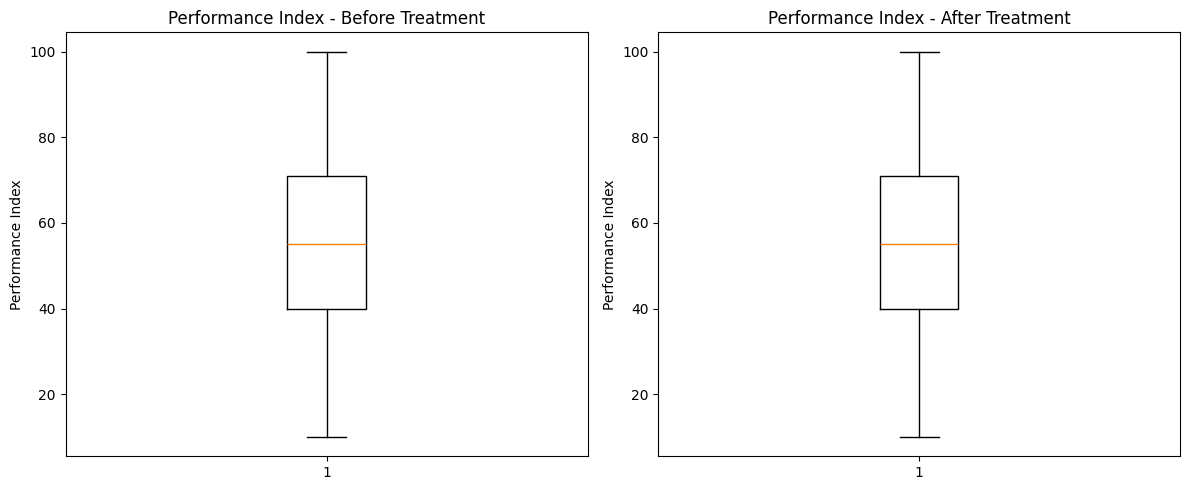

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

# Loading the local file available in the environment
file_path = "/content/Student_Performance.csv"
df = pd.read_csv(file_path)

print("First 5 rows of the dataset:")
print(df.head())

print("\nDataset shape:")
print(df.shape)

# Selecting an existing numerical score/performance column from the dataset
target_col = "Performance Index" if "Performance Index" in df.columns else "Previous Scores"
data = df[target_col].dropna()

print(f"\nNumber of {target_col} values:", len(data))
Q1 = data.quantile(0.25)
Q3 = data.quantile(0.75)
IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("\nIQR METHOD ")
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

iqr_outliers = df[
    (df[target_col] < lower_limit) |
    (df[target_col] > upper_limit)
]

print(f"Number of IQR outliers in {target_col}:", len(iqr_outliers))

mean = data.mean()
std = data.std()
df["Z_score"] = (df[target_col] - mean) / std

z_outliers = df[abs(df["Z_score"]) > 3]

print("\nZ-SCORE METHOD")
print("Mean:", mean)
print("Standard deviation:", std)
print(f"Number of Z-score outliers in {target_col}:", len(z_outliers))

print("\nIQR OUTLIERS")
if len(iqr_outliers) > 0:
    print(iqr_outliers[[target_col]])
else:
    print(f"No IQR outliers found in {target_col}.")

print("\n Z-SCORE OUTLIERS ")
if len(z_outliers) > 0:
    print(z_outliers[[target_col, "Z_score"]])
else:
    print(f"No Z-score outliers found in {target_col}.")

target_col_treated = f"{target_col.replace(' ', '_').lower()}_treated"
df[target_col_treated] = df[target_col].clip(
    lower=lower_limit,
    upper=upper_limit
)

print(f"Treatment method: Capping using IQR limits")

print("\n BEFORE TREATMENT ")
print(df[target_col].describe())

print("\n AFTER TREATMENT ")
print(df[target_col_treated].describe())

comparison = df[
    [target_col, target_col_treated]
]
print(comparison.head(20))

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.boxplot(df[target_col].dropna())
plt.title(f"{target_col} - Before Treatment")
plt.ylabel(target_col)
plt.subplot(1, 2, 2)
plt.boxplot(df[target_col_treated].dropna())
plt.title(f"{target_col} - After Treatment")
plt.ylabel(target_col)
plt.tight_layout()
plt.show()